[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the data

In [6]:
# Read the CSV using default parsing, skipping any structurally malformed lines if they exist
df = pd.read_csv('athlete_events.csv', on_bad_lines='skip')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


### Don't forget to drop duplicates first

In [8]:
df= df.drop_duplicates()
df.shape

(269731, 15)

# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [9]:
df.isna().sum()

,0
ID,0
Name,0
Sex,0
Age,9315
Height,58814
Weight,61527
Team,0
NOC,0
Games,0
Year,0


### Number of males and females

In [10]:
df['Sex'].value_counts()

,count
Sex,
M,195353
F,74378


### How many cities do we have and what are they ?

In [12]:
c= df['City'].unique()
print(len(c))
c

42


array(['Barcelona', 'London', 'Antwerpen', 'Paris', 'Calgary',
       'Albertville', 'Lillehammer', 'Los Angeles', 'Salt Lake City',
       'Helsinki', 'Lake Placid', 'Sydney', 'Atlanta', 'Stockholm',
       'Sochi', 'Nagano', 'Torino', 'Beijing', 'Rio de Janeiro', 'Athina',
       'Squaw Valley', 'Innsbruck', 'Sarajevo', 'Mexico City', 'Munich',
       'Seoul', 'Berlin', 'Oslo', "Cortina d'Ampezzo", 'Melbourne',
       'Roma', 'Amsterdam', 'Montreal', 'Moskva', 'Tokyo', 'Vancouver',
       'Grenoble', 'Sapporo', 'Chamonix', 'St. Louis', 'Sankt Moritz',
       'Garmisch-Partenkirchen'], dtype=object)

# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year

In [13]:
num= df.groupby('Year')['ID'].nunique()
num

,ID
Year,
1896,176
1900,1224
1904,650
1906,841
1908,2024
1912,2409
1920,2676
1924,3565
1928,3703


### Which athlete participated the most? (his/her name and ID)

In [15]:
ath= df.groupby('Name')['ID'].nunique()
a= ath.idxmax()
a

'Ivan Ivanov'

# <font color='red'>**Advanced level**</fond>

### Find the number of each medal for each year.
##### The output should look like this
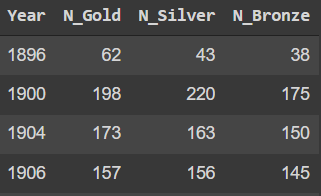

In [23]:
result = pd.crosstab(df['Year'], df['Medal'])

result = result[['Gold', 'Silver', 'Bronze']].rename(
    columns={
        'Gold': 'N_Gold',
        'Silver': 'N_Silver',
        'Bronze': 'N_Bronze'
    }
)
result.head()

Medal,N_Gold,N_Silver,N_Bronze
Year,,,
1896,62,43,38
1900,198,220,175
1904,173,163,150
1906,157,156,145
1908,294,281,256


# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

In [24]:
gold_by_city = df[df['Medal'] == 'Gold']['City'].value_counts()
print(gold_by_city)

City
London                    1215
Athina                     883
Los Angeles                726
Beijing                    671
Rio de Janeiro             665
Sydney                     663
Atlanta                    608
Barcelona                  559
Seoul                      520
Antwerpen                  493
Paris                      475
Moskva                     457
Montreal                   438
Munich                     404
Mexico City                359
Tokyo                      347
Stockholm                  338
Berlin                     312
Roma                       309
Helsinki                   306
Melbourne                  290
Amsterdam                  245
Sochi                      202
Torino                     176
Vancouver                  174
St. Louis                  173
Salt Lake City             162
Nagano                     145
Innsbruck                  131
Lillehammer                110
Lake Placid                104
Albertville                104
Cal

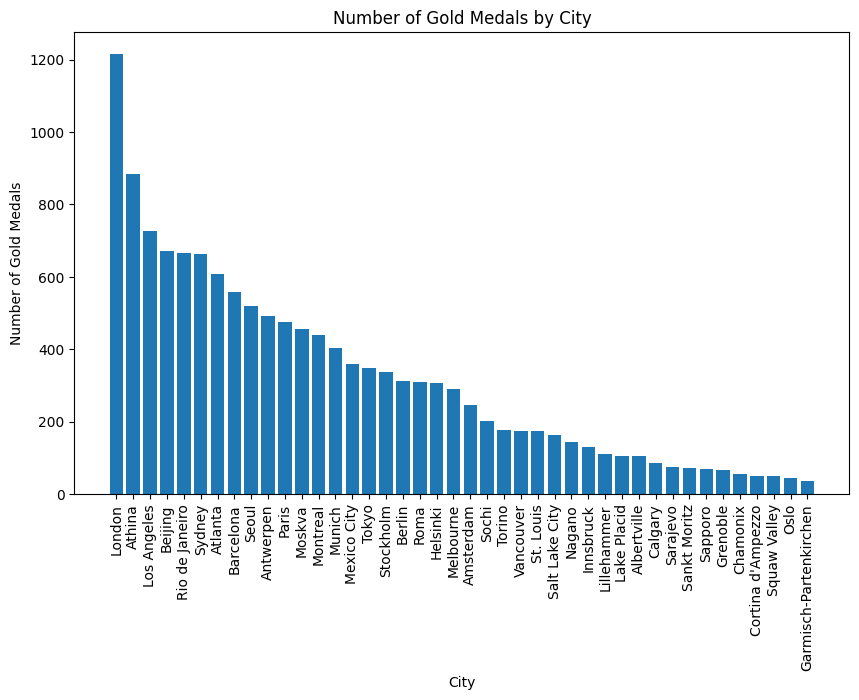

In [27]:
plt.figure(figsize=(10, 6))
plt.bar(gold_by_city.index, gold_by_city.values)
plt.xlabel('City')
plt.ylabel('Number of Gold Medals')
plt.title('Number of Gold Medals by City')
plt.xticks(rotation=90)
plt.show()


### Find the total missing data for each year?

In [31]:
missing_by_year = df.isna().groupby(df['Year']).sum().sum(axis=1)
print(missing_by_year)

Year
1896     1065
1900     5676
1904     3331
1906     5022
1908     8057
1912    10018
1920    11175
1924    15194
1928    14124
1932     6308
1936    18433
1948    20008
1952    22943
1956    13531
1960    10407
1964     9710
1968     9663
1972    11331
1976    10819
1980     8706
1984    11307
1988    14802
1992    20759
1994     3207
1996    15638
1998     3337
2000    12067
2002     3707
2004    11515
2006     3878
2008    11866
2010     3908
2012    11507
2014     4532
2016    12064
dtype: int64


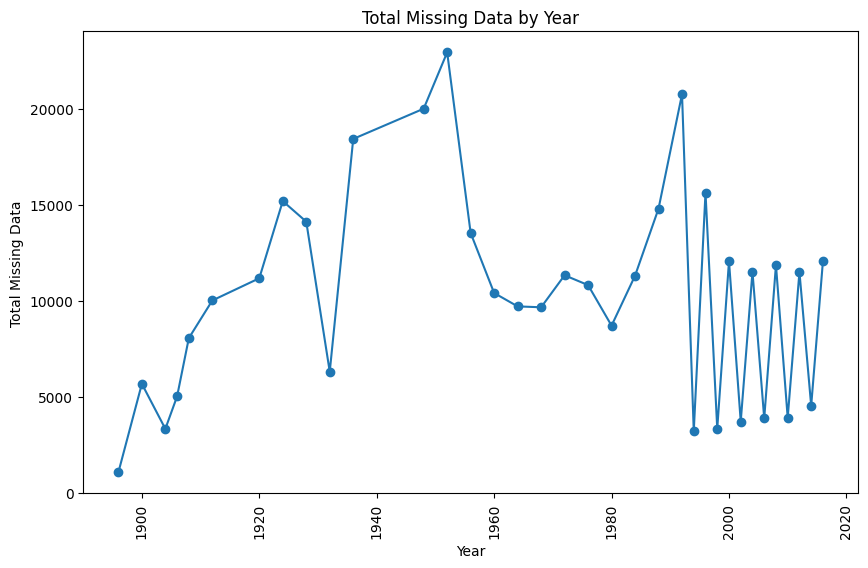

In [32]:
plt.figure(figsize=(10, 6))
plt.plot(missing_by_year.index, missing_by_year.values, marker='o')
plt.xlabel('Year')
plt.ylabel('Total Missing Data')
plt.title('Total Missing Data by Year')
plt.xticks(rotation=90)
plt.show()

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

**Yes it changed, based on the plot below**

In [34]:
athletes_count = (
    df.groupby(['Year', 'Season'])['ID']
    .nunique()
    .unstack(fill_value=0)
)

athletes_count

Season,Summer,Winter
Year,,
1896,176,0
1900,1224,0
1904,650,0
1906,841,0
1908,2024,0
1912,2409,0
1920,2676,0
1924,3256,313
1928,3247,461


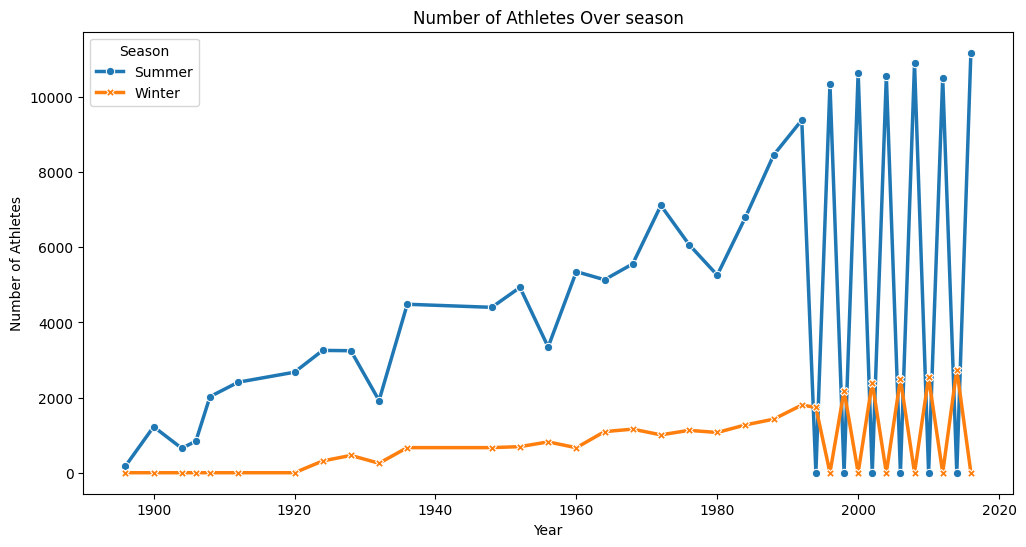

In [36]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=athletes_count, markers=True, dashes=False, linewidth=2.5)

plt.title('Number of Athletes Over season')
plt.xlabel('Year')
plt.ylabel('Number of Athletes')
plt.show()